Autoenconder Variacional (VAE)
----

~~~
Extracción de Características en Imágenes.
Master en Ciencia de Datos e Ingeniería de Computadores.
Universidad de Granada.

Francisco Javier Sáez Maldonado - fjaviersaezm@ugr.es
Rafael Molina Soriano - rms@decsai.ugr.es

Créditos: Francisco Miguel Castro Macías, Fernando Pérez Bueno
~~~

En este guión veremos la implementación de un Autoencoder Variacional (VAE) en Pytorch. Te dejamos algunos enlaces útiles:

- En esta publicación de towardsdatascience.com (https://towardsdatascience.com/intuitively-understanding-variational-autoencoders-1bfe67eb5daf) hay una explicación muy intuitiva sobre VAEs y contiene algunos de los ejemplos que se han mencionado en clase. 
- En este enlace puedes visualizar el contenido del espacio latente de una VAE entrenada con MNIST: http://taylordenouden.com/VAE-Latent-Space-Explorer/.
- Si quieres aprender más sobre Pytorch, te recomendamos que mires este repositorio de Miguel López Pérez y Andrea Morales Garzón, en el que se explica cómo desarrollar una aplicación en Pytorch: https://github.com/wizmik12/first-app-pytorch

# Una breve introducción a las redes neuronales

Tal vez nunca antes te hayan hablado de redes neuronales. A continuación vamos a hacer un pequeño resumen de las ideas más básicas. 

Una red neuronal es una composición de funciones. En este guión vamos a trabajar con las redes neuronales más sencillas. En algunos libros las llaman "perceptrón multicapa" o "feedforward network". Se definen así:
$$ \begin{cases}
    \mathbf{x}_0 \in \mathbb{R}^{d_0}, \\ 
    \mathbf{x}_k = h\left(\mathbf{W}_k \mathbf{x}_{k-1} \right), \quad k \in \{ 1, 2, \ldots, K\},
    \end{cases}
$$
donde $\mathbf{W}_k \in \mathbb{R}^{d_{k} d_{k-1}}$ y $h \colon \mathbb{R} \to \mathbb{R}$ es una función que se aplica componente a componente. Si llamamos $f_k(\mathbf{x}) = h(\mathbf{W}_k \mathbf{x})$, tenemos que una red neuronal es la aplicación:
$$ f(\mathbf{x}; \mathbf{W}) = (f_K \circ \cdots \circ f_1)(\mathbf{x}).$$
No te asustes por la definición, es una cosa muy simple: partimos de un vector inicial $\mathbf{x}_0$, lo multiplicamos por una matriz y le aplicamos $h$. En el siguiente paso partimos del vector que hemos obtenido, y aplicamos el mismo procedimiento. Esto lo repetimos $K$ pasos.

La función $h$ se llama "función de activación". Es importante que esta función sea no lineal, ya que así la red podrá aprender funciones mucho más complejas. En este guión vamos a usar la función RELU,
$$ h(x) = \begin{cases} 
    x & \text{si} & x\geq0, \\
    0 & \text{si} & x < 0.
    \end{cases}
$$

Las matrices $\mathbf{W}_k$ son los parámetros de la red. Entrenar una red neuronal consiste en encontrar los mejores parámetros de acuerdo a algún criterio. Imagínate que estamos en un problema de regresión en el que cada ejemplo $\mathbf{x}_i$ está acompañado de una etiqueta $y_i \in \mathbb{R}$. Lo que nos gustaría es encontrar aquellos parámetros que minimicen
$$ \mathcal{L}(\mathbf{W}) = \sum_{i}(f(\mathbf{x}_i, \mathbf{W}) - y_i)^2.$$
A $\mathcal{L}$ se le llama función de pérdida. Si las funciones $h$ son diferenciables (o casi) $\mathcal{L}(\mathbf{W})$ será diferenciable y podemos emplear técnicas basadas en gradiente descendente. El gradiente descendente es un método iterativo para optimizar funciones diferenciables. Para minimizar $\mathcal{L}(\mathbf{W})$, la versión básica de gradiente descendente consiste en aplicar las actualizaciones: 
$$ \mathbf{W}_{k+1} = \mathbf{W}_k - \eta \nabla_\mathbf{W} \mathcal{L}(\mathbf{W}_k) $$

A $\eta$ se le denomina *learning rate*. Los gradientes $\nabla_\mathbf{W} \mathcal{L}(\mathbf{W}_k)$ en una red neuronal se calculan mediante técnicas de "diferenciación automática". Seguro que te suena el algoritmo "backpropagation". Estas técnicas (y la propia evaluación de redes neuronales) son costosas computacionalmente, pero altamente paralelizables. Por ello, el uso de GPUs puede agilizar enormemente el entrenamiento y la inferencia. Librerías como Pytorch y Tensorflow ofrecen una interfaz para poder entrenar redes neuronales en GPUs sin tener que preocuparnos por cómo se realiza esta paralelización a bajo nivel. Sin embargo, sí que debemos tener una idea general del procedimiento. Tanto los parámetros $\mathbf{W}$ como los ejemplos de entrenamiento deben de cargarse en la GPU. Sin embargo, las GPUs tienen una memoria limitada, por lo que (normalmente) no se pueden cargar todos los ejemplos a la vez. Lo que se suele hacer es que los ejemplos se agrupan en *batches*, los cuales se cargan y se procesan en la GPU por separado. 

En resumen, para entrenar una red neuronal necesitamos especificar:
1. La estructura de la red. 
2. La función de pérdida.

Vamos a ver que Pytorch nos permite hacer estas cosas de forma muy natural. Lo primero que hacemos es cargar todas las librerías que vamos a usar.

In [2]:
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from tqdm import tqdm

print("Versión de Pytorch:", torch.__version__)

Versión de Pytorch: 2.11.0+cpu


Las librerías como Tensorflow y Pytorch ofrecen funcionalidades para poder entrenar nuestros modelos en tarjetas gráficas usando el software CUDA. Si hemos configurado Pytorch correctamente y CUDA tiene acceso a las tarjetas, las siguientes líneas mostrarán el nombre de la tarjeta (o tarjetas) disponibles.

In [2]:
print("CUDA:", torch.cuda.is_available())
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    print("Device name: ", torch.cuda.get_device_name())

CUDA: False


Vamos a fijar el tamaño de batch y el número de épocas que entrenaremos la red.

In [3]:
BATCH_SIZE = 128
EPOCHS = 30

# Conjunto de datos: MNIST

El conjunto de datos de caras que venimos utilizando se nos queda un poco pequeño para entrenar una red neuronal. Además, comprenderemos mucho mejor la estructura del espacio latente de un Autoencoder si usamos datos que tengan distintas etiquetas. En esta ocasión vamos a trabajar con el conjunto MNIST, que probablemente ya conozcas. Se trata de imágenes 28x28 de números manuscritos, con un total de 70.000 muestras.

`torchvision` ofrece distintos conjuntos que podemos usar con una sóla línea. MNIST es uno de ellos:

In [4]:
dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=torchvision.transforms.ToTensor())
print(dataset)

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()


Como vemos, el conjunto MNIST tiene 60.000 ejemplos. Vamos a ver qué formato tiene un ejemplo:

In [5]:
img, label = dataset[2]
print("img:", img.shape)
print("max:", img.max(), "min:", img.min())
print("label:", label)

img: torch.Size([1, 28, 28])
max: tensor(1.) min: tensor(0.)
label: 4


Son imágenes de un sólo canal (escala de grises) y dimensiones 28x28. Además, todos los ejemplos se encuentran normalizados. Vamos a inspeccionar 8 ejemplos aleatorios.

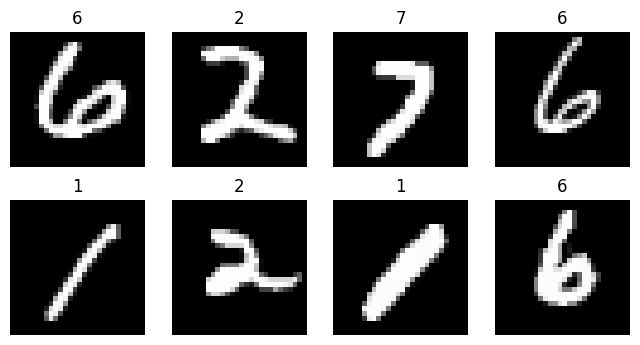

In [6]:
figure = plt.figure(figsize=(8, 4))
cols, rows = 4, 2
for i in range(1, cols * rows + 1):
    idx = np.random.randint(0, len(dataset))
    img, label = dataset[idx]
    figure.add_subplot(rows, cols, i)
    plt.title(label)
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

El objeto `DataLoader` de Pytorch nos permite recorrer un dataset de forma eficiente, dividiéndolo automáticamente en batches. 

In [7]:
dataloader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

# Autoencoder determinista

Lo primero que vamos a hacer es construir un autoencoder determinista. Primero vamos a repasar qué es. Como sabéis, un Autoencoder tiene dos partes: un codificador (Encoder) y un decodificador (Decoder). Vamos a denotar el espacio de entrada por $\mathcal{X} \subset \mathbb{R}^D$ y el espacio latente por $\mathcal{Z} \subset \mathbb{R}^d$. 

Podemos entender el Encoder como una aplicación $f_E \colon \mathcal{X} \to \mathcal{Z}$ y el Decoder como una aplicación $f_D \colon \mathcal{Z} \to \mathcal{X}$. El Autoencoder es entonces la composición de ambas, $f = f_D \circ f_E \colon \mathcal{X} \to \mathcal{X}$.

Para definir una red en Pytorch debemos crear una clase que herede de `torch.nn.Module`. Podemos entender que un modelo en Pytorch implementa una función $g$, y el método `forward(x)` se corresponde con $g(x)$. 

In [8]:
class Encoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super(Encoder, self).__init__()
        self.encoder = torch.nn.Sequential(
            torch.nn.Linear(in_features=28*28, out_features=100), # [B, 100]
            torch.nn.ReLU(), # [B, 100]
            torch.nn.Linear(in_features=100, out_features=50), # [B, 50]
            torch.nn.ReLU(), # [B, 50]
            torch.nn.Linear(in_features=50, out_features=latent_dim), # [B, latent_dim]
        )
    
    def forward(self, x): # x: [B, 1, 28, 28]
        x = x.view(x.size(0), -1) # [B, 1*28*28]
        z = self.encoder(x) # z: [B, latent_dim]
        return z

> 📝 **Pregunta 1 (1 punto).** ¿Qué pasaría en el espacio latente si aplicamos una RELU a la salida del codificador?

Al aplicar una función RELU a la salida del codificador, estamos imponiendo que todas las dimensiones del espacio latente sean no negativas. Esto significa que cualquier valor negativo generado por el codificador se establecerá en cero. Como resultado, el espacio latente se restringirá a un subconjunto del espacio original contenido en $\left(\mathbb{R}^+_0\right)^d$.

Esta limitación podría implicar que el modelo no pueda representar ciertas características de los datos de entrada, especialmente si las relaciones entre las características requieren valores negativos para capturar la variabilidad completa.

Ahora construimos el decodificador. 

In [9]:
class Decoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super(Decoder, self).__init__()
        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(in_features=latent_dim, out_features=50), # [B, 50]
            torch.nn.ReLU(), # [B, 50]
            torch.nn.Linear(in_features=50, out_features=100), # [B, 100]
            torch.nn.ReLU(), # [B, 100]
            torch.nn.Linear(in_features=100, out_features=28*28), # [B, 28*28]
            torch.nn.Sigmoid() # [B, 28*28]
        )
        
    def forward(self, z): # z: [B, latent_dim]
        x_rec = self.decoder(z) # x_rec: [B, 1*28*28]
        x_rec = x_rec.view(x_rec.size(0), 1, 28, 28) # x_rec: [B, 1, 28, 28]
        return x_rec

> 📝 **Pregunta 2 (1 punto).** ¿Por qué hemos usado en la última capa del decodificador una función sigmoide?

La función sigmoide se utiliza en la última capa del decodificador porque queremos que la salida del autoencoder esté en el rango [0, 1], que es el rango de los valores de píxeles normalizados de las imágenes de entrada. Valores de píxeles fuera de este rango no serían válidos para representar imágenes.

Y el Autoencoder, que dentro tiene el Encoder y el Decoder.

In [10]:
class Autoencoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super(Autoencoder, self).__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)
    
    def forward(self, x): # x: [B, 1, 28, 28]
        z = self.encoder(x) # z: [B, latent_dim]
        x_rec = self.decoder(z) # x_rec: [B, 1, 28, 28]
        return x_rec

¿Qué función de error tenemos que usar? Lo que nos gustaría que pasara es que el Autoencoder reconstruyera cualquier ejemplo a la perfección, es decir, que $f(\mathbf{x})=\mathbf{x}$. Esto es equivalente a que $\| f(\mathbf{x}) - \mathbf{x} \|^2 = 0$. Lo que queremos entonces es minimizar la diferencia entre la imagen original y la salida del Autoencoder:
$$ \mathcal{L}_{\mathrm{MSE}} = \sum_{i} \| \mathbf{x}_i - f(\mathbf{x}_i)\|^2 $$

> 📝 **Pregunta 3 (1 punto).** ¿Qué forma deben tener $f_E(\mathbf{x})$ y $f_D(\mathbf{z})$ para recuperar PCA al minimizar la función anterior?

Con el objetivo de recuperar PCA al minimizar la función de error $\mathcal{L}_{\mathrm{MSE}}$, las funciones $f_E(\mathbf{x})$ y $f_D(\mathbf{z})$ deben ser afines; es decir, deben tener la forma:
- $f_E(\mathbf{x}) = \mathbf{W}_E \mathbf{x} + b_E$ para el codificador, donde $\mathbf{W}_E$ es una matriz de pesos que proyecta los datos de entrada a un espacio latente de menor dimensión, y $b_E$ es un vector de sesgo.
- $f_D(\mathbf{z}) = \mathbf{W}_D \mathbf{z} + b_D$ para el decodificador, donde $\mathbf{W}_D$ es una matriz de pesos que reconstruye los datos desde el espacio latente de vuelta al espacio original, y $b_D$ es un vector de sesgo.

Para lograr esto, ambas redes neuronales deben tener capas lineales sin funciones de activación (la función de activación debe ser la identidad). Esto permitirá que el autoencoder aprenda una representación lineal de los datos, similar a lo que hace PCA, y minimice la pérdida de reconstrucción de manera efectiva.

In [11]:
def mse_loss_fn(x, x_rec): # x: [B, 1, 28, 28], x_rec: [B, 1, 28, 28]
    return torch.nn.functional.mse_loss(x, x_rec, reduction='sum')

La función `train_ae` implementa un bucle de entrenamiento típico de Pytorch. Fíjate que usamos la librería `tqdm` para mostrar barras de progreso. Además, guardamos y devolvemos las métricas de entrenamiento en cada época.

In [12]:
def train_ae(model, dataloader, optimizer, epochs=10):
    metrics_dic = {'rec_loss': []}
    for epoch in range(1,epochs+1):
        rec_loss_sum = 0 
        pbar = tqdm(enumerate(dataloader), total=len(dataloader))
        pbar.set_description(f"Epoch {epoch} - Training")
        for batch_idx, batch in pbar:
            x, _ = batch
            x = x.to(DEVICE)
            x_rec = model(x)
            rec_loss = mse_loss_fn(x, x_rec)
            optimizer.zero_grad()
            rec_loss.backward()
            optimizer.step()
            rec_loss_sum += rec_loss.item()
            pbar.set_postfix({'rec_loss' : rec_loss_sum / (batch_idx+1)})
        rec_loss_avg = rec_loss_sum / len(dataloader)
        metrics_dic['rec_loss'].append(rec_loss_avg)
    return model, metrics_dic

Vamos a entrenar el Autoencoder para que genere un espacio latente de dos dimensiones. Para poder entrenar un modelo necesitamos definir un optimizador. En Pytorch hay muchos, pero vamos a elegir Adam. 

In [13]:
model_ae = Autoencoder(latent_dim=2).to(DEVICE)
opt = torch.optim.Adam(model_ae.parameters())
model_ae.train()
model_ae, _ = train_ae(model_ae, dataloader, opt, epochs=EPOCHS)

Epoch 30 - Training: 100%|██████████| 469/469 [00:08<00:00, 54.77it/s, rec_loss=3.8e+3] 


> 📝 **Pregunta 4 (1 punto).** ¿Cuántas iteraciones (step) hay en cada época? ¿Por qué? 

Una época consiste en recorrer todo el conjunto de datos una vez. Puesto que el conjunto de datos de entrenamiento MNIST tiene 60000 ejemplos y hemos definido un tamaño de batch de 128, el número de iteraciones (steps) por época se calcula como el número total de ejemplos dividido por el tamaño del batch. En el caso de que resulten decimales, se redondea hacia arriba, ya que el último batch puede contener menos ejemplos. Por lo tanto, el número de iteraciones por época es:
$$ \text{Número de iteraciones por época} = \left\lceil \frac{60000}{128} \right\rceil = \left\lceil 468.75 \right\rceil = 469 $$

Como hemos diseñado nuestro modelo para que el espacio latente tenga 2 componentes, podemos visualizarlo. Aplicamos a cada ejemplo el Encoder que hemos entrenado. 

In [14]:
x = dataset.data.unsqueeze(1).float().to(DEVICE)
labels = dataset.targets
z_ae = model_ae.encoder(x).detach().cpu().numpy()
print(z_ae.shape)

(60000, 2)


A cada punto obtenido (en el espacio latente) le asignamos el color que corresponde con su etiqueta. De esto se encarga la función `plot_label_clusters`. También podemos visualizar la reconstrucción que hace el decodificador de cada punto del espacio latente. La función `plot_latent_space` reconstruye el cuadrado $\left[-s, s \right]^2$ del espacio latente, estando $s$ especificado por el parámetro `scale`.

In [15]:
def plot_label_clusters(fig, ax, z, labels, scale=1.0):
    cmap = plt.get_cmap('tab10', len(np.unique(labels)))
    s = ax.scatter(z[:, 0], z[:, 1], c=labels, cmap=cmap)
    ax.set_xlabel("z[0]")
    ax.set_ylabel("z[1]")
    fig.colorbar(s, ax=ax, ticks=range(len(np.unique(labels))))
    rectangle = plt.Rectangle((-scale,-scale), 2*scale, 2*scale, ec="black", fill=False)
    ax.add_patch(rectangle)
    ax.axis("equal")

def plot_latent_space(fig, ax, model, scale=1.0, n=15):
    size = 28
    img = np.zeros((size * n, size * n))
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.from_numpy(np.array([[xi, yi]])).to(DEVICE).float()
            x_rec = model.decoder(z)[0].reshape(size, size).detach().cpu().numpy()
            img[i*size : (i+1)*size, j*size : (j+1)*size,] = x_rec

    start_range = size // 2
    end_range = n * size + start_range
    pixel_range = np.arange(start_range, end_range, size)
    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)
    ax.imshow(img, cmap="Greys_r")
    ax.set_xticks(pixel_range, sample_range_x, rotation=90)
    ax.set_yticks(pixel_range, sample_range_y)
    ax.set_xlabel("z[0]")
    ax.set_ylabel("z[1]")

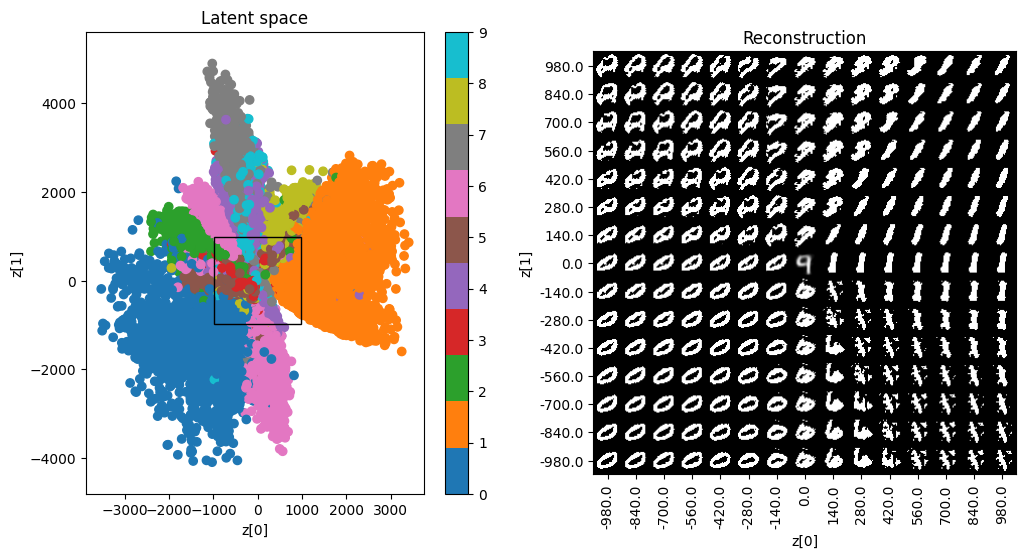

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
scale = 0.2*np.max(np.abs(z_ae))
plot_label_clusters(fig, ax[0], z_ae, labels.numpy(), scale=scale)
ax[0].set_title("Latent space")
plot_latent_space(fig, ax[1], model_ae, scale=scale)
ax[1].set_title("Reconstruction")
plt.show()

> 📝 **Pregunta 5 (1 punto).** ¿Podríamos interpolar *correctamente* entre cualesquiera dos ejemplos y tener la certeza de que el resultado tendrá *sentido*? ¿Por qué?

No, no podemos interpolar correctamente entre cualesquiera dos ejemplos y tener la certeza de que el resultado tendrá sentido. Esto se debe a que el espacio latente aprendido por un autoencoder determinista no sigue una distribución continua o estructurada. La interpolación lineal entre dos puntos en el espacio latente puede llevarnos a regiones que no corresponden a datos válidos del conjunto de entrenamiento, lo que puede resultar en reconstrucciones que no tengan sentido o que no representen características coherentes de los datos originales.


> 📝 **Pregunta 6 (1 punto).** ¿Qué clases están mejor *separadas*? ¿Qué ocurriría si cambiamos la dimensión del espacio latente?

En el espacio latente, las clases que están mejor separadas son aquellas cuyos puntos de datos tienen características más distintivas y menos solapamiento con otras clases. Por ejemplo, en este caso, las clases de dígitos como '1' y '0' tienden a estar mejor separadas debido a sus formas únicas y consistentes. Por otro lado, dígitos como '5' y '6' pueden tener más solapamiento debido a sus similitudes en ciertas representaciones.

Si cambiamos la dimensión del espacio latente, esto afectará la capacidad del modelo para capturar y representar las características de los datos.
- Una dimensión más alta podría permitir una mejor separación de las clases, ya que el modelo tendría más capacidad para aprender representaciones complejas. Sin embargo, también podría llevar a un sobreajuste si la dimensión es demasiado alta en relación con la cantidad de datos disponibles.
- Una dimensión más baja podría forzar al modelo a aprender representaciones más compactas, lo que podría resultar en una pérdida de información y una mayor superposición entre las clases, dificultando la separación de las mismas en el espacio latente.

# Autoencoder variacional

Ahora vamos a construir un Autoencoder Variacional (Variational AutoEncoder, VAE). Denotamos por $\mathbf{x}$ a las variables del espacio $\mathcal{X}$ y por $\mathbf{z}$ a las variables del espacio latente $\mathcal{Z}$. Un VAE es un modelo probabilístico, cuya distribución conjunta escribimos como
$$p(\mathbf{x}, \mathbf{z}) = p(\mathbf{z}) p(\mathbf{x} \mid \mathbf{z}).$$
La forma de las distribuciones $p(\mathbf{z})$ y $p(\mathbf{x} \mid \mathbf{z})$ las elegimos nosotros:
$$p(\mathbf{z}) = \mathcal{N}(\mathbf{z} \mid \mathbf{0}, \mathbf{I}), \quad p(\mathbf{x} \mid \mathbf{z}) = \mathcal{N}(\mathbf{x} \mid f_D(\mathbf{z}), \sigma^2 \mathbf{I}).$$
Nuestro objetivo es *codificar* las imágenes. Para ello, tenemos que conocer la distribución $p(\mathbf{z} \mid \mathbf{x})$. Sin embargo, si elegimos que $f_D$ sea una red neuronal, no sabemos calcularla de forma analítica. 

> 📝 **Pregunta 7 (1 punto).** ¿Qué forma debe de tener $f_D(\mathbf{z}$) para recuperar PPCA al ajustar los parámetros por máxima verosimilitud?

Al igual que en el caso del autoencoder determinista, para recuperar PPCA al ajustar los parámetros por máxima verosimilitud, la función $f_D(\mathbf{z})$ debe ser una función afín. Es decir, debe tener la forma:
$$f_D(\mathbf{z}) = \mathbf{W}\mathbf{z} + \mathbf{b}$$
donde $\mathbf{W}$ es una matriz de pesos y $\mathbf{b}$ es un vector de sesgo.

Lo que hacemos es aproximar $p(\mathbf{z} \mid \mathbf{x})$ por una distribución 
$$ q(\mathbf{z} \mid \mathbf{x}) = \mathcal{N}(\mathbf{z} \mid m_E(\mathbf{x}), \mathrm{diag}(s_E(\mathbf{x})^2),$$
donde $m_E$ y $s_E$ son redes neuronales. Podemos entender que el codificador ahora tiene la siguiente estructura:
$$ f_E(\mathbf{x}) = \left[ m_E(\mathbf{x}), s_E(\mathbf{x})^2 \right].$$


In [17]:
class VarEncoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super(VarEncoder, self).__init__()
        self.encoder = torch.nn.Sequential(
            torch.nn.Linear(in_features=28*28, out_features=100), # [B, 100]
            torch.nn.ReLU(), # [B, 100]
            torch.nn.Linear(in_features=100, out_features=50), # [B, 50]
            torch.nn.ReLU(), # [B, 50]
        )

        self.encoder_mean = torch.nn.Sequential(
            torch.nn.Linear(in_features=50, out_features=latent_dim), # [B, latent_dim]
        )
        self.encoder_log_var = torch.nn.Sequential(
            torch.nn.Linear(in_features=50, out_features=latent_dim), # [B, latent_dim]
        )
    
    def forward(self, x):
        x = x.view(x.size(0), -1) # x: [B, 1*28*28]
        z = self.encoder(x) # z: [B, 50]
        z_mean = self.encoder_mean(z) # z_mean: [B, latent_dim]
        z_log_var = self.encoder_log_var(z) # z_log_var: [B, latent_dim]
        return z_mean, z_log_var

Fíjate que ahora la salida del codificador no es un sólo "objeto", sino dos. Creamos el VAE de la misma forma que el determinista:

In [18]:
class VarAutoencoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super(VarAutoencoder, self).__init__()
        self.encoder = VarEncoder(latent_dim)
        self.decoder = Decoder(latent_dim)
    
    def forward(self, x):
        z_mean, z_log_var = self.encoder(x)
        return self.decoder(z_mean)

¿Cómo elegimos los parámetros de $f_E$ y $f_D$ para que $q(\mathbf{z} \mid \mathbf{x})$ aproxime correctamente a $p(\mathbf{z} \mid \mathbf{x})$?. Empleando el enfoque de inferencia variacional, buscamos maximizar una cota inferior sobre la verosimilitud, que se llama Evidence Lower BOund (ELBO):
$$ \sum_i \log p(\mathbf{x}_i) \geq \mathrm{ELBO}$$
Nuestra función de pérdida será entonces el ELBO con el signo cambiado:
$$ \mathcal{L} = - \mathrm{ELBO} = \mathcal{L}_{\mathrm{KL}} + \mathcal{L}_{\mathrm{MSE}}$$
donde 
$$ 
\mathcal{L}_{\mathrm{MSE}} = - \sum_{i} \mathbb{E}_{q(\mathbf{z} \mid \mathbf{x}_i)}\left[ \log p( \mathbf{x}_i \mid \mathbf{z}) \right] \approx \sum_{i} \| \mathbf{x}_i - f_D(\mathbf{z}_{i})\|^2, \quad \mathbf{z}_{i} \sim  \mathcal{N}(m_E(\mathbf{x}_i), \mathrm{diag}(s_E(\mathbf{x}_i))), \\
\mathcal{L}_{\mathrm{KL}} = \sum_{i} D_{\mathrm{KL}}(q(\mathbf{z} \mid \mathbf{x}_i), p(\mathbf{z})) = \sum_{i} \frac{1}{2}\left( \| m_E(\mathbf{x}_i) \|^2 + \| s_E(\mathbf{x}_i) \|^2 - \sum_j \log(s_E(\mathbf{x}_i)_j^2) - 1 \right).
$$

In [19]:
def kl_loss_fn(z_mean, z_log_var):    
    return 0.5 * torch.sum(-1 - z_log_var + z_mean**2 + torch.exp(z_log_var))

> 📝 **Pregunta 8 (2 puntos).** Supongamos que `X` e `Y` son tensores de forma (shape) `[A, B, C, D]`. Indica qué forma tienen los tensores que devuelven las siguientes operaciones (tendrás que leer la documentación de Pytorch):

> - `torch.mse_loss(X, Y, reduction='none')`

Si `X` e `Y` son tensores de forma `[A, B, C, D]`, la operación `torch.mse_loss(X, Y, reduction='none')` devuelve un tensor de la misma forma `[A, B, C, D]`, puesto que calcula el error cuadrático elemento a elemento entre los tensores `X` e `Y`, sin realizar ninguna reducción (como suma o promedio) sobre los elementos del tensor resultante. Por lo tanto, la salida mantiene la misma forma que los tensores de entrada. 

Pongamos un ejemplo concreto numérico. `X` e `Y` representan dos batches de shape `[A,B,C,D]`, donde:
- `A` es el tamaño del batch,
- `B` es el número de canales (por ejemplo, 1 para imágenes en escala de grises, 3 para imágenes RGB),
- `C` y `D` son las dimensiones espaciales de la imagen (por ejemplo, 28x28 para imágenes de MNIST).

Para este ejemplo, supondremos `A=2`, `B=1`, `C=2`, y `D=2`, es decir, dos batches de dos imágenes de 2x2 píxeles en escala de grises. Entonces, `X` e `Y` podrían ser:
$$
X = \begin{bmatrix}
\begin{bmatrix}\begin{pmatrix}
1 & 2 \\
3 & 4
\end{pmatrix}\end{bmatrix},
\begin{bmatrix}\begin{pmatrix}
5 & 6 \\
7 & 8
\end{pmatrix}\end{bmatrix}
\end{bmatrix}, \quad
Y = \begin{bmatrix}
\begin{bmatrix}\begin{pmatrix}
1 & 1 \\
1 & 1
\end{pmatrix}\end{bmatrix},
\begin{bmatrix}\begin{pmatrix}
5 & 5 \\
5 & 6
\end{pmatrix}\end{bmatrix}
\end{bmatrix}
$$

De esta manera, `torch.mse_loss(X, Y, reduction='none')` calcularía el error cuadrático elemento a elemento entre `X` e `Y`, resultando en el siguiente tensor de la misma forma `[2, 1, 2, 2]`:
$$
\text{MSE Loss} = \begin{bmatrix}
\begin{bmatrix}\begin{pmatrix}
0 & 1 \\
4 & 9
\end{pmatrix}\end{bmatrix},
\begin{bmatrix}\begin{pmatrix}
0 & 1 \\
4 & 4
\end{pmatrix}\end{bmatrix}
\end{bmatrix}
$$

> - `torch.sum(torch.mse_loss(X, Y, reduction='none'), dim=[2])`

Dado un tensor `D` de forma `[A, B, C, D]`, la operación `torch.sum(D, dim=[2])` suma los elementos a lo largo de la dimensión `C`. Esto significa que el resultado tendrá una forma `[A, B, D]`, ya que la dimensión `C` se ha reducido mediante la suma. Con el ejemplo anterior, si aplicamos `torch.sum(torch.mse_loss(X, Y, reduction='none'), dim=[2])`, obtendremos un tensor de forma `[2, 1, 2]`, donde cada elemento representa la suma de los errores cuadráticos a lo largo de la dimensión `C` (las filas de las imágenes).
$$
\text{Sum MSE Loss} = \begin{bmatrix}
\begin{bmatrix}\begin{pmatrix}
4 & 10 \\
\end{pmatrix}\end{bmatrix},
\begin{bmatrix}\begin{pmatrix}
4 & 5 \\
\end{pmatrix}\end{bmatrix}
\end{bmatrix}
$$

> - `torch.sum(torch.mse_loss(X[0,:,:,:], Y[1,:,:,:], reduction='none'), dim=[2])`

En este caso, `X[0,:,:,:]` selecciona el primer ejemplo del batch de `X`, por lo que su dimensión será `[B, C, D]`. De manera similar, `Y[1,:,:,:]` selecciona el segundo ejemplo del batch de `Y`, también resultando en un tensor de forma `[B, C, D]`. Por tanto, `torch.mse_loss(X[0,:,:,:], Y[1,:,:,:], reduction='none')` devolverá un tensor de forma `[B, C, D]`. Luego, al aplicar `torch.sum(..., dim=[2])`, se sumarán los elementos a lo largo de la dimensión `D`, resultando en un tensor de forma `[B, C]`. En este caso, todos los elementos de `D` se suman y se almacenan como un único valor para cada combinación de `B` y `C`. Por lo tanto, el resultado final tendrá la forma `[B, C]`.

Definimos el bucle para entrenar el VAE.

In [20]:
def train_vae(model, dataloader, optimizer, epochs=10):
    metrics_dic = {'rec_loss': [], 'kl_loss': []}
    for epoch in range(1, epochs+1):
        rec_loss_sum = 0
        kl_loss_sum = 0
        pbar = tqdm(enumerate(dataloader), total=len(dataloader))
        pbar.set_description(f"Epoch {epoch} - Training")
        for batch_idx, batch in pbar:
            x, _ = batch
            x = x.to(DEVICE)
            z_mean, z_log_var = model.encoder(x)
            z_sd = torch.exp(0.5*z_log_var)
            z_sample = z_mean + z_sd*torch.randn_like(z_mean)
            x_rec = model.decoder(z_sample)
            rec_loss = mse_loss_fn(x, x_rec)
            kl_loss = kl_loss_fn(z_mean, z_log_var)
            loss = rec_loss + kl_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            rec_loss_sum += rec_loss.item()
            kl_loss_sum += kl_loss.item()
            pbar.set_postfix({'rec_loss' : rec_loss_sum / (batch_idx+1), 'kl_loss' : kl_loss_sum / (batch_idx+1)})
        rec_loss_avg = rec_loss_sum / len(dataloader)
        kl_loss_avg = kl_loss_sum / len(dataloader)
        metrics_dic['rec_loss'].append(rec_loss_avg)
        metrics_dic['kl_loss'].append(kl_loss_avg)   
    return model

> 📝 **Pregunta 9 (1 punto).** ¿Dónde estamos empleando la trampa de la reparametrización? ¿Puedes explicar qué estamos haciendo en esa línea?

La trampa de la reparametrización se está empleando en la línea donde generamos la variable latente `z` a partir de la media `mu` y la desviación estándar `std` obtenidas del codificador. Lo directo sería muestrear `z` directamente de la distribución `q(z|x)`; es decir, emplear:
```python
z = torch.normal(mu, std)
```
Sin embargo, esto no es diferenciable con respecto a los parámetros del codificador; es decir, no sabemos cuánto afecta ``mu` y `std` a la pérdida final, lo que impide que podamos actualizar los parámetros del codificador mediante backpropagation. No podemos calcular:
$$ \dfrac{\partial z}{\partial \mu} \quad \text{ni} \quad \dfrac{\partial z}{\partial \sigma}.$$



Es por ello que usamos la trampa de la reparametrización, que consiste en expresar `z` como una función determinista de `mu`, `std` y una variable aleatoria `epsilon` que sigue una distribución normal estándar. De esta forma:
$$ z(\mu, \sigma) = \mu + \sigma \cdot \epsilon, \quad \epsilon \sim \mathcal{N}(0, 1) $$
$$ \dfrac{\partial z}{\partial \mu} = 1, \quad \dfrac{\partial z}{\partial \sigma} = \epsilon $$

Al tener estas derivadas parciales, podemos propagar el gradiente a través de `z` y actualizar los parámetros del codificador durante el entrenamiento.

Entrenamos el VAE:

In [21]:
model_vae = VarAutoencoder(latent_dim=2).to(DEVICE)
opt = torch.optim.Adam(model_vae.parameters())
model_vae.train()
model_vae = train_vae(model_vae, dataloader, opt, epochs=EPOCHS)

Epoch 30 - Training: 100%|██████████| 469/469 [00:08<00:00, 57.57it/s, rec_loss=3.94e+3, kl_loss=633]


> 📝 **Pregunta 10 (1 punto).** ¿Por qué el error de reconstrucción decrece mientras que la divergencia de Kullback-Leibler crece?

Hay un trade-off entre la reconstrucción de los datos y la regularización del espacio latente.
- Minimizar el error de reconstrucción implica que el modelo se enfoque en aprender a reconstruir los datos de entrada lo más fielmente posible. Esto lleva a que la distribución latente `q(z|x)` se aleje de la distribución prior `p(z)`, puesto que se busca diferenciar lo máximo posible los distintos ejemplos de entrada para mejorar la reconstrucción.
- Maximizar la divergencia de Kullback-Leibler implica que el modelo se enfoque en hacer que la distribución latente `q(z|x)` se acerque a la distribución prior `p(z)`. Esto puede llevar a que el modelo pierda capacidad para diferenciar entre distintos ejemplos de entrada, lo que puede aumentar el error de reconstrucción.

Debido a este trade-off, es común que no sea posible minimizar ambos términos simultáneamente. Debido a que el error de reconstrucción es un orden de magnitud mayor que la divergencia de Kullback-Leibler, el modelo tiende a priorizar la minimización del error de reconstrucción puesto que es el término más influyente en la función de pérdida total.

Inspeccionamos el espacio latente del VAE. 

In [22]:
x = dataset.data.unsqueeze(1).float().to(DEVICE)
labels = dataset.targets
z_vae, _ = model_vae.encoder(x)
z_vae = z_vae.detach().cpu().numpy()

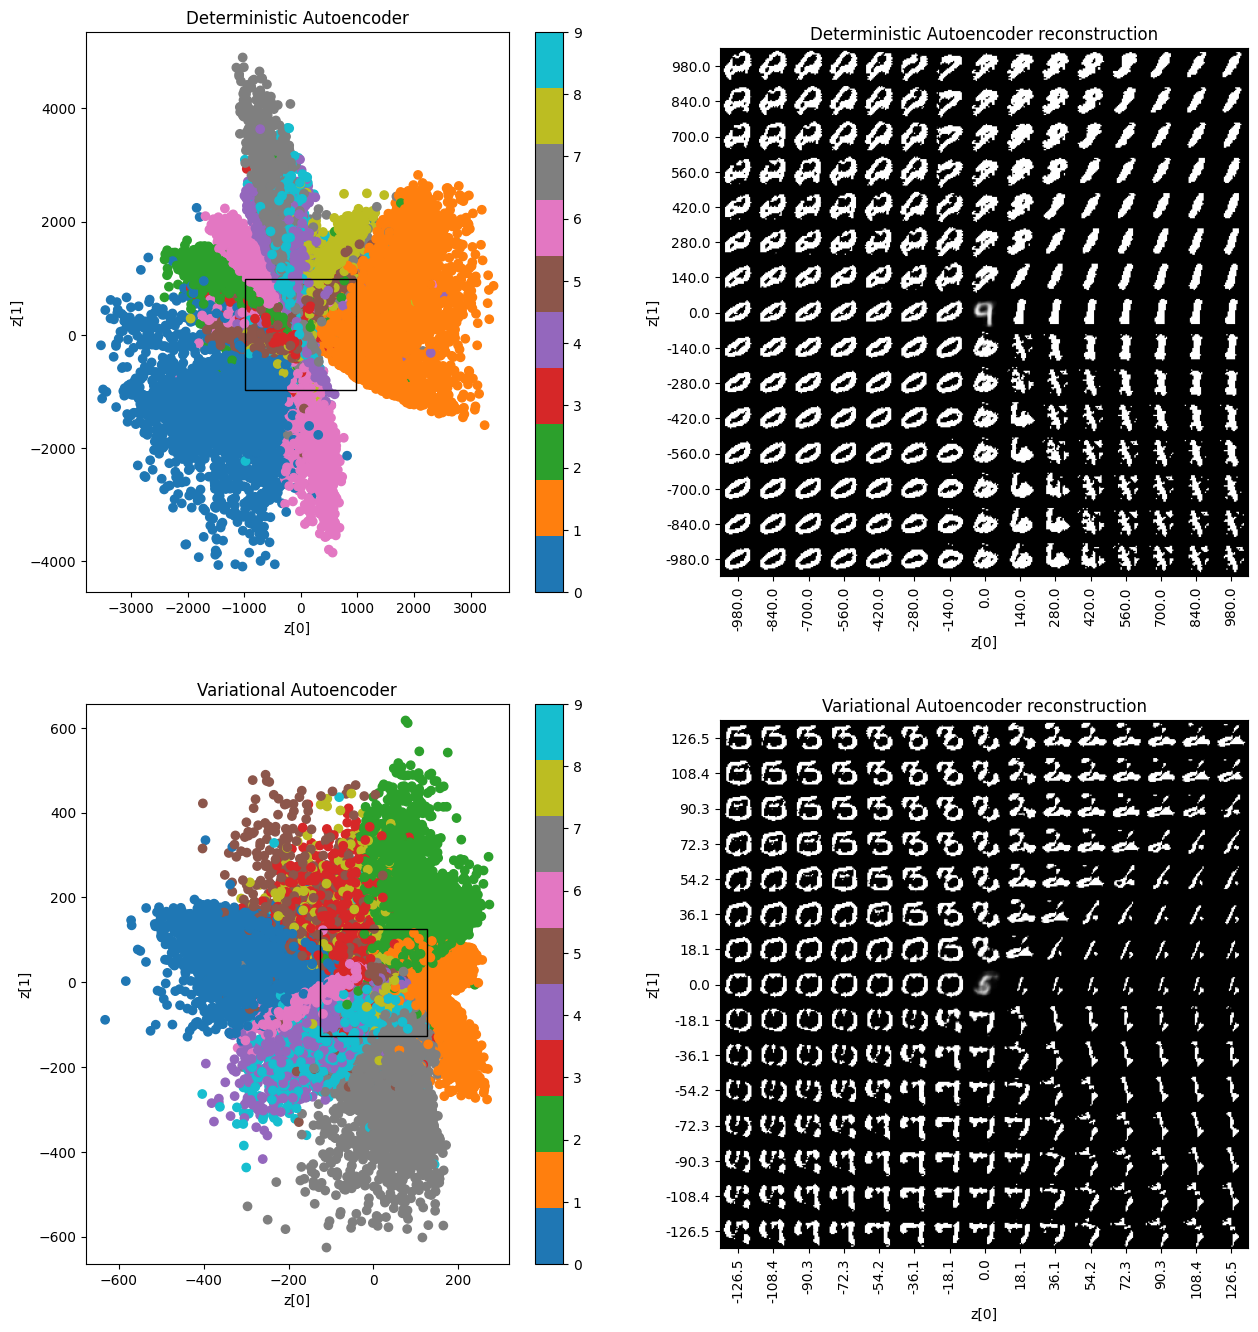

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(15, 16))
scale_ae = 0.2*np.max(np.abs(z_ae))
scale_vae = 0.2*np.max(np.abs(z_vae))
plot_label_clusters(fig, ax[0,0], z_ae, labels.numpy(), scale=scale_ae)
ax[0,0].set_title("Deterministic Autoencoder")
plot_label_clusters(fig, ax[1,0], z_vae, labels.numpy(), scale=scale_vae)
ax[1,0].set_title("Variational Autoencoder")
plot_latent_space(fig, ax[0,1], model_ae, scale=scale_ae)
ax[0,1].set_title("Deterministic Autoencoder reconstruction")
plot_latent_space(fig, ax[1,1], model_vae, scale=scale_vae)
ax[1,1].set_title("Variational Autoencoder reconstruction")
plt.show()

> 📝 **Pregunta 11 (1 punto).** Compara el espacio latente del Autoencoder variacional con el del Autoencoder determinista. ¿Qué ha ocurrido al incluir el término $\mathcal{L}_{\mathrm{KL}}$ en la función de pérdida? ¿Por qué es necesario incluirlo?

Al comparar el espacio latente del Autoencoder variacional con el del Autoencoder determinista, se observa que el espacio latente del VAE tiende a ser más estructurado y continuo. En el VAE, los puntos correspondientes a diferentes clases están más agrupados y distribuidos de manera más uniforme en el espacio latente, mientras que en el autoencoder determinista, los puntos pueden estar más dispersos y menos organizados.

El objetivo del último ejercicio es usar inferencia variacional y la trampa de la reparametrización para estimar los parámetros de un modelo PPCA muy sencillo.

Vamos a suponer que $\mathcal{X}=\mathbb{R}^2$ y $\mathcal{Z}=\mathbb{R}$. Tomamos
$$ 
p(z) = \mathcal{N}(z \mid 0, 1), \\
p(\mathbf{x} \mid z) = \mathcal{N}(\mathbf{x} \mid \mathbf{w} z, \sigma_n^2 \mathbf{I}).
$$
Observa que como estamos intentando emular un modelo PPCA tomaremos $q(z \mid \mathbf{x})=\mathcal{N}(z \mid \mathbf{m}^\top \mathbf{x}, \sigma_p^2 \mathbf{I})$ y nuestro objetivo es estimar $ \boldsymbol{\Theta} = \{ \mathbf{w}, \mathbf{m}, \sigma_p, \sigma_n\}$ para que $q(z \mid \mathbf{x})$ aproxime a $p(z \mid \mathbf{x})$.

Vamos a empezar generando las muestras. 

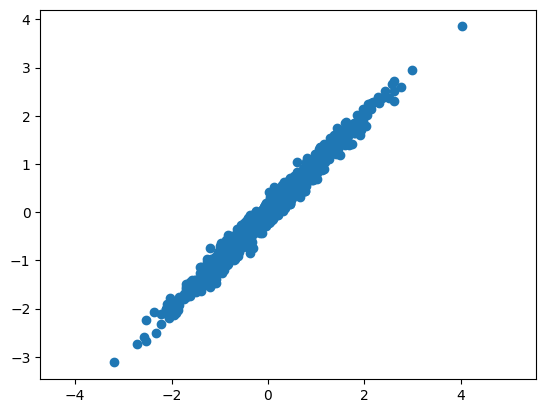

In [6]:
np.random.seed(42)
N = 1000

mean, sigma_prior = 0, 1 # Media y varianza de la a priori p(z) = N(0, 1)
Z = np.random.normal(mean, sigma_prior, N)  # N muestras de la a priori p(z)
w_exact = np.array([[1],[1]])

sigma_n_exact=0.1

# Generamos muestras de la a posteriori p(x|z) = N(x|wz, sigma_noise^2 I)
X = Z*w_exact+np.random.normal(mean, sigma_n_exact, 2*N).reshape(2,N)

plt.plot(X[0],X[1],'o')
plt.axis('equal')
plt.show()

Nuestro conjunto de entrenamiento será `X`. Observa que, si estimamos $\boldsymbol{\Theta}$ correctamente, recuperaremos los parámetros que hemos fijado para generar las muestras. 

> 📝 **Pregunta 12 (4 puntos).** Para estimar $\boldsymbol{\Theta}$ buscamos maximizar el ELBO. Esto es equivalente a minimizar el ELBO con el signo cambiado, que toma la siguiente forma:

> $$\mathcal{L} = \sum_{i=1}^N \left[ D_{\mathrm{KL}}(q(z \mid \mathbf{x}_i), p(z)) - \mathbb{E}_{q(z \mid \mathbf{x}_i)}\left[ \log p( \mathbf{x}_i \mid z) \right] \right]$$

> Exprésalo como una función de los parámetros a estimar. Para el primer sumando debes usar la expresión de la Divergencia de Kullback-Leibler entre dos distribuciones normales. Para el segundo debes usar la trampa de la reparametrización. 

Buscamos en primer lugar resolver el primer sumando.

Dadas dos distribuciones normales unidimensionales $p_1(x)\sim \mathcal{N}(\mu_1, \sigma_1^2)$ y $p_2(x)\sim \mathcal{N}(\mu_2, \sigma_2^2)$, buscamos obtener la fórmula para la Divergencia de Kullback-Leibler entre ellas:
$$
D_{\text{KL}}(p_1 \parallel p_2) = \mathbb{E}_{p_1}\left[ \log \frac{p_1(x)}{p_2(x)} \right] = \mathbb{E}_{p_1}\left[ \log p_1(x) - \log p_2(x) \right]
$$

Las funciones de densidad de probabilidad de $p_1$ y $p_2$ son:
$$
p_i(x) = \frac{1}{\sqrt{2\pi\sigma_i^2}} \exp\left(-\frac{(x - \mu_i)^2}{2\sigma_i^2}\right)
$$

Por tanto, tenemos que:
$$
\log p_i(x) = -\frac{1}{2} \log(2\pi) - \log(\sigma_i) - \frac{(x - \mu_i)^2}{2\sigma_i^2}
$$

Restando estas expresiones, obtenemos:
$$
\log p_1(x) - \log p_2(x) = -\log(\sigma_1) + \log(\sigma_2) - \frac{(x - \mu_1)^2}{2\sigma_1^2} + \frac{(x - \mu_2)^2}{2\sigma_2^2}
$$

Buscamos ahora la esperanza de esta expresión bajo $p_1$. Teniendo en cuenta la linealidad de la esperanza y que $\mathbb{E}_{p_1}[(x - \mu_1)^2] = \sigma_1^2$, el único término que necesitamos calcular es $\mathbb{E}_{p_1}[(x - \mu_2)^2]$. Sumando y restando $\mu_1$ dentro del cuadrado, obtenemos:
$$
(x - \mu_2)^2 = (x - \mu_1 + \mu_1 - \mu_2)^2 = (x - \mu_1)^2 + 2(x - \mu_1)(\mu_1 - \mu_2) + (\mu_1 - \mu_2)^2
$$

Teniendo en cuenta que $\mathbb{E}_{p_1}[x - \mu_1] = 0$, obtenemos:
$$
\mathbb{E}_{p_1}[(x - \mu_2)^2] = \sigma_1^2 + (\mu_1 - \mu_2)^2
$$

Uniendo todo, obtenemos la expresión final de la Divergencia de Kullback-Leibler entre dos distribuciones normales unidimensionales:
$$
D_{\text{KL}}(p_1 \parallel p_2) = \log\left(\frac{\sigma_2}{\sigma_1}\right) - \frac{1}{2} + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2\sigma_2^2} 
= \dfrac{1}{2} \left[ \log\left(\frac{\sigma_2^2}{\sigma_1^2}\right) + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{\sigma_2^2} - 1 \right]
$$

Puesto que $p_1=q(z \mid \mathbf{x}_i)\sim \mathcal{N}(m^\top \mathbf{x}_i, \sigma_p^2)$ y $p_2=p(z)\sim \mathcal{N}(0, 1)$, tenemos que:
$$
D_{\text{KL}}(q(z \mid \mathbf{x}_i) \parallel p(z)) = \dfrac{1}{2} \left[ \log\left(\frac{1}{\sigma_p^2}\right) + \frac{\sigma_p^2 + (m^\top \mathbf{x}_i)^2}{1} - 1 \right] = \dfrac{1}{2} \left[ -\log(\sigma_p^2) + \sigma_p^2 + (m^\top \mathbf{x}_i)^2 - 1 \right]
$$

Buscamos ahora el segundo sumando, es decir, calcular $\mathbb{E}_{q(z \mid \mathbf{x}_i)}\left[ \log p( \mathbf{x}_i \mid z) \right]$.
Dado que $p(\mathbf{x}_i \mid z) \sim \mathcal{N}(\mathbf{x}_i \mid \mathbf{w} z, \sigma_n^2 \mathbf{I})$, tenemos que:
$$
p(\mathbf{x}_i \mid z) = (2\pi)^{-D/2}((\sigma_n^2)^D)^{-1/2} \exp\left(-\frac{\|\mathbf{x}_i - \mathbf{w} z\|^2}{2\sigma_n^2}\right)
= (2\pi\sigma_n^2)^{-D/2} \exp\left(-\frac{\|\mathbf{x}_i - \mathbf{w} z\|^2}{2\sigma_n^2}\right)
$$

Puesto que en este caso $D=2$, tenemos que:
$$
p(\mathbf{x}_i \mid z) = \dfrac{1}{2\pi\sigma_n^2} \exp\left(-\frac{\|\mathbf{x}_i - \mathbf{w} z\|^2}{2\sigma_n^2}\right)
$$

Aplicando logaritmo, obtenemos:
$$
\log p(\mathbf{x}_i \mid z) = -\log(2\pi\sigma_n^2) - \frac{\|\mathbf{x}_i - \mathbf{w} z\|^2}{2\sigma_n^2}
$$

Por lo tanto, tenemos que:
$$
\mathbb{E}_{q(z \mid \mathbf{x}_i)}\left[ \log p( \mathbf{x}_i \mid z) \right] = -\log(2\pi\sigma_n^2) - \frac{1}{2\sigma_n^2} \mathbb{E}_{q(z \mid \mathbf{x}_i)}\left[ \|\mathbf{x}_i - \mathbf{w} z\|^2 \right]
$$

Aplicamos la trampa de la reparametrización, es decir, escribimos $z = m^\top \mathbf{x}_i + \sigma_p \epsilon$, donde $\epsilon \sim \mathcal{N}(0, 1)$. Entonces:
$$
\mathbb{E}_{q(z \mid \mathbf{x}_i)}\left[ \|\mathbf{x}_i - \mathbf{w} z\|^2 \right] = \mathbb{E}_{\epsilon \sim \mathcal{N}(0, 1)}\left[ \|\mathbf{x}_i - \mathbf{w} (m^\top \mathbf{x}_i + \sigma_p \epsilon)\|^2 \right]
= \mathbb{E}_{\epsilon \sim \mathcal{N}(0, 1)}\left[ \|\mathbf{x}_i - \mathbf{w} m^\top \mathbf{x}_i - \mathbf{w} \sigma_p \epsilon\|^2 \right]
$$

Para terminar, calculamos la esperanza de este término. Separamos lo que acompaña a $\epsilon$ y lo que no, definiendo $\mathbf{a} = \mathbf{x}_i - \mathbf{w} m^\top \mathbf{x}_i$ y $\mathbf{b} = \mathbf{w} \sigma_p$. Entonces, usando que $\mathbb{E}[\epsilon] = 0$ y $\mathbb{E}[\epsilon^2] = \mathbb{E[(\epsilon - 0)^2]} = 1$, tenemos que:
$$
\mathbb{E}_{\epsilon \sim \mathcal{N}(0, 1)}\left[ \|\mathbf{a} - \mathbf{b} \epsilon\|^2 \right] = \mathbb{E}_{\epsilon \sim \mathcal{N}(0, 1)}\left[ \|\mathbf{a}\|^2 - 2 \mathbf{a}^\top \mathbf{b} \epsilon + \|\mathbf{b}|^2 \epsilon^2 \right] = \|\mathbf{a}\|^2 + \|\mathbf{b}\|^2
$$

Por tanto, tenemos que:
$$
\mathbb{E}_{q(z \mid \mathbf{x}_i)}\left[ \log p( \mathbf{x}_i \mid z) \right] = -\log(2\pi\sigma_n^2) - \frac{1}{2\sigma_n^2} \left( \|\mathbf{x}_i - \mathbf{w} m^\top \mathbf{x}_i\|^2 + \|\mathbf{w} \sigma_p\|^2 \right)
$$

Factorizando $-\frac{1}{2}$, obtenemos:
$$
\mathbb{E}_{q(z \mid \mathbf{x}_i)}\left[ \log p( \mathbf{x}_i \mid z) \right] = -\frac{1}{2} \left[ 2\log(2\pi\sigma_n^2) + \frac{\|\mathbf{x}_i - \mathbf{w} m^\top \mathbf{x}_i\|^2 + \|\mathbf{w} \sigma_p\|^2}{\sigma_n^2} \right]
$$

Por tanto, la función de pérdida final $\mathcal{L}$ como función de los parámetros a estimar $\boldsymbol{\Theta} = \{ \mathbf{w}, \mathbf{m}, \sigma_p, \sigma_n\}$ es:
$$
\mathcal{L}(\mathbf{w}, \mathbf{m}, \sigma_p, \sigma_n) = \sum_{i=1}^N \left[ \frac{1}{2} \left[ -\log(\sigma_p^2) + \sigma_p^2 + (m^\top \mathbf{x}_i)^2 - 1 \right] + \frac{1}{2} \left[ 2\log(2\pi\sigma_n^2) + \frac{\|\mathbf{x}_i - \mathbf{w} m^\top \mathbf{x}_i\|^2 + \|\mathbf{w} \sigma_p\|^2}{\sigma_n^2} \right] \right]
$$

Sacando el factor $\frac{1}{2}$, podemos simplificar la expresión final de la función de pérdida:
$$
\mathcal{L}(\mathbf{w}, \mathbf{m}, \sigma_p, \sigma_n) = \frac{1}{2} \sum_{i=1}^N \left[ -\log(\sigma_p^2) + \sigma_p^2 + (m^\top \mathbf{x}_i)^2 - 1 + 2\log(2\pi\sigma_n^2) + \frac{\|\mathbf{x}_i - \mathbf{w} m^\top \mathbf{x}_i\|^2 + \|\mathbf{w} \sigma_p\|^2}{\sigma_n^2} \right]
$$

> 📝 **Pregunta 13 (4 puntos).** Ahora que la has expresado como una función de los parámetros a estimar, tienes que encontrar aquellos parámetros que la minimizan. Esto es lo que debes hacer en este apartado. Te ofrecemos dos alternativas:
> Alternativa (a): calcula manualmente las derivadas respecto de cada parámetro y aplica el método del gradiente descendente.
> Alternativa (b): usa las funcionalidades que ofrece Pytorch. A continuación tienes un ejemplo para minimizar la función $x \mapsto x^2 -4x + 3$.

In [4]:
x = torch.Tensor([3.0])
x.requires_grad = True
opt = torch.optim.Adam([x], lr=.01)
for i in range(10000):
    opt.zero_grad()
    loss = x**2 - 4*x + 3
    loss.backward()
    opt.step()
print("Final value of x:", x.item())

Final value of x: 2.0


In [23]:
def loss_fn(w, m, sigma_p, sigma_n, X):
    D, N = X.shape  # D: número de dimensiones (2 en este caso), N: número de muestras (1000 en este caso)
    
    # Aseguramos que las desviaciones estándar no bajen de un épsilon mínimo, puesto que el logaritmo de cero no está definido y puede causar problemas numéricos.
    sigma_p_clamp = torch.clamp(sigma_p, min=1e-5)
    sigma_n_clamp = torch.clamp(sigma_n, min=1e-5)
    
    # 1. Pérdida KL
    kl_loss = 0.5 * torch.sum(-2.0 * torch.log(sigma_p_clamp) + sigma_p_clamp**2 + (m.T @ X)**2 - 1.0)
    
    # 2. Pérdida de reconstrucción
    norm_term_1 = torch.linalg.norm(X - w @ m.T @ X, dim=0)**2
    norm_term_2 = torch.linalg.norm(w * sigma_p_clamp)**2
    
    rec_loss = 0.5 * torch.sum(
        2.0 * torch.log(2.0 * np.pi * sigma_n_clamp**2) + 
        (norm_term_1 + norm_term_2) / (sigma_n_clamp**2)
    )
    
    return kl_loss + rec_loss

X_torch = torch.from_numpy(X).float()
w = torch.tensor([[0.1], [0.1]], requires_grad=True)
m = torch.tensor([[0.0], [0.0]], requires_grad=True)
log_sigma_p = torch.tensor([0.0], requires_grad=True)
log_sigma_n = torch.tensor([0.1], requires_grad=True)

opt = torch.optim.Adam([w, m, log_sigma_p, log_sigma_n], lr=0.01)

num_epochs = 5000
pbar = tqdm(range(num_epochs), desc="Optimizando VAE/PPCA")

for i in pbar:
    opt.zero_grad()
    sigma_p = torch.exp(log_sigma_p)
    sigma_n = torch.exp(log_sigma_n)
    loss = loss_fn(w, m, sigma_p, sigma_n, X_torch)
    loss.backward()
    opt.step()
    
    # Actualizar la barra con el valor de pérdida actual cada 50 pasos
    if i % 50 == 0:
        pbar.set_postfix({"Loss": f"{loss.item():.2f}", "sigma_n": f"{sigma_n.item():.4f}"})


sigma_p_final = torch.exp(log_sigma_p).item()
sigma_n_final = torch.exp(log_sigma_n).item()

print("\n" + "="*40)
print(" Estimación de parámetros usando Inferencia Variacional (VI)")
print("="*40)
print("Final value of w:\n", w.detach().numpy())
print("Final value of m:\n", m.detach().numpy())
print("Final value of sigma_p:", round(sigma_p_final, 4))
print("Final value of sigma_n:", round(sigma_n_final, 4))

Optimizando VAE/PPCA: 100%|██████████| 5000/5000 [00:11<00:00, 440.50it/s, Loss=857.91, sigma_n=0.0996]


 Estimación de parámetros usando Inferencia Variacional (VI)
Final value of w:
 [[0.97407407]
 [0.9799852 ]]
Final value of m:
 [[0.50622356]
 [0.50929797]]
Final value of sigma_p: 0.0719
Final value of sigma_n: 0.0997


En este caso, los parámetros estimados se han determinado empleando Inferencia Variacional. No obstante,también se pueden obtener mediante el método de máxima verosimilitud.
- Los valores exactos de los parámetros $\mathbf{w}$ y $\sigma_n$ son los mismos que los valores fijados para generar las muestras, es decir, $\mathbf{w} = [1, 1]^\top$ y $\sigma_n = 0.01$.
- La distribución a posteriori $p(z \mid \mathbf{x})$ se demuestra que es:
$$
p(z \mid \mathbf{x}) = \mathcal{N}\left(z \mid M^{-1} \mathbf{w}^\top \mathbf{x}, \sigma_n^2 M^{-1}\right), \quad M = \mathbf{w}^\top \mathbf{w} + \sigma_n^2\mathbf{I}
$$

Por tanto, los valores exactos de los parámetros $\mathbf{m}$ y $\sigma_p$ son:
$$
\mathbf{m} = M^{-1} \mathbf{w}^\top, \quad \sigma_p = \sqrt{\sigma_n^2 M^{-1}}
$$

In [28]:
M_exact = (w_exact.T @ w_exact + sigma_n_exact**2 * np.eye(1))[0,0]

m_exact = (1.0 / M_exact) * w_exact
sigma_p_exact = np.sqrt((sigma_n_exact**2) / M_exact)

print("\n" + "="*40)
print(" Estimación de parámetros por máxima verosimilitud")
print("="*40)
print("Exact value of w:\n", w_exact)
print("Exact value of m:\n", m_exact)
print("Exact value of sigma_p:", round(sigma_p_exact, 4))
print("Exact value of sigma_n:", round(sigma_n_exact, 4))


 Estimación de parámetros por máxima verosimilitud
Exact value of w:
 [[1]
 [1]]
Exact value of m:
 [[0.49751244]
 [0.49751244]]
Exact value of sigma_p: 0.0705
Exact value of sigma_n: 0.1


Como podemos ver, los errores relativos de los parámetros estimados respecto a los valores exactos son muy pequeños, lo que indica que la estimación ha sido precisa.

In [31]:
error_w = np.linalg.norm(w.detach().numpy() - w_exact) / np.linalg.norm(w_exact)
error_m = np.linalg.norm(m.detach().numpy() - m_exact) / np.linalg.norm(m_exact)
error_sigma_p = abs(sigma_p_final - sigma_p_exact) / abs(sigma_p_exact)
error_sigma_n = abs(sigma_n_final - sigma_n_exact) / abs(sigma_n_exact)

print("\n" + "="*40)
print(" Errores relativos de los parámetros estimados respecto a los valores exactos (%)")
print("="*40)
print("Relative error of w:", round(error_w * 100, 4), "%")
print("Relative error of m:", round(error_m * 100, 4), "%")
print("Relative error of sigma_p:", round(error_sigma_p * 100, 4), "%")
print("Relative error of sigma_n:", round(error_sigma_n * 100, 4), "%")


 Errores relativos de los parámetros estimados respecto a los valores exactos (%)
Relative error of w: 2.316 %
Relative error of m: 2.083 %
Relative error of sigma_p: 1.9549 %
Relative error of sigma_n: 0.3274 %


El objetivo del ejercicio era ver si el VAE calcula correctamente los parámetros de un modelo PPCA muy sencillo a partir de solo las muestras generadas `X`. Hemos visto que, efectivamente, los parámetros estimados son muy cercanos a los valores exactos, lo que demuestra la eficacia del enfoque de Inferencia Variacional para estimar los parámetros de modelos probabilísticos complejos.